## Cél

Ez a notebook a bevezetett champion stratégia (`lgbm_solusdt_l_fw60_2101_2605` /
`lgbm_solusdt_s_fw60_2101_2605`, deployment `strat_solusdt_fw60_combo_2101_2605`,
aktiválva 2026-06-23) long/short signal-gyakoriságát hasonlítja össze a
kalibrációs/backtest periódus (2025-05-01 – 2026-05-31) és az élő, bevezetés
utáni periódus (2026-06-23 – ma) között, heti bontásban.

Vizsgált területek:
- heti signal-gyakoriság long/short bontásban a kalibrációs periódusban (tényleges `strat.*__trades`)
- heti signal-gyakoriság long/short bontásban élesen (rank-percentile + entry_cutoff újraszámítva a live futási logika szerint)
- a csökkenés időzítése: bevezetés előtt kezdődött-e, vagy a bevezetéssel egy időben lépett fel
- implementációs hiba kizárása: model stamp, NULL predikció, feature NaN ráta élőben vs kalibráción
- piaci rezsim (volatilitás) összehasonlítás a két periódus között

**Kapcsolódó dokumentáció:**
- Módszertan: `_doc_/methodology_doc/6100_strategy_calibration.md`, `_doc_/methodology_doc/6200_short_score_semantics.md`, `_doc_/methodology_doc/6300_strategy_grid_search.md`
- Kód-dokumentáció: `_doc_/database_and_code_doc/7100_live_trading.md`, `_doc_/database_and_code_doc/7150_trading_state_strategy.md`

**Asset:** SOLUSDT | **Granularitás:** 1m | **Dátum:** 2026-08-12

In [1]:
from __future__ import annotations

import sys
from pathlib import Path

import duckdb
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# _root = repo gyoker; felfele navigal amig meg nem talalja az analyst/ mappat
_root = Path.cwd()
while not (_root / "analyst").exists() and _root != _root.parent:
    _root = _root.parent

sys.path.insert(0, str(_root))
sys.path.insert(0, str(_root / "src"))
from analyst.lib.table_formatting import display_analysis_table
import analyst.lib.db_utils as dbu
import utils

CQ_COLORS = {
    "blue":       "#1696d2",
    "black":      "#000000",
    "gray_dark":  "#353535",
    "gray":       "#696969",
    "gray_light": "#d2d2d2",
    "yellow":     "#fdbf11",
    "orange":     "#f15a24",
    "red":        "#ec008b",
}
CQ_SEQUENCE = [
    CQ_COLORS["blue"],
    CQ_COLORS["yellow"],
    CQ_COLORS["orange"],
    CQ_COLORS["gray"],
    CQ_COLORS["red"],
]

sns.set_theme(
    style="whitegrid",
    rc={
        "figure.figsize": (9, 5.5),
        "figure.dpi": 120,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.edgecolor": CQ_COLORS["gray"],
        "axes.labelcolor": CQ_COLORS["gray_dark"],
        "xtick.color": CQ_COLORS["gray_dark"],
        "ytick.color": CQ_COLORS["gray_dark"],
        "grid.color": CQ_COLORS["gray_light"],
        "grid.linewidth": 0.8,
        "axes.axisbelow": True,
        "legend.frameon": False,
    },
)
sns.set_palette(CQ_SEQUENCE)

LONG_MODEL_ID = "lgbm_solusdt_l_fw60_2101_2605"
SHORT_MODEL_ID = "lgbm_solusdt_s_fw60_2101_2605"
LONG_CUTOFF = 0.98
SHORT_CUTOFF = 0.94
FIT_START = "2025-05-01"
FIT_END = "2026-05-31"

ARTIFACTS = _root / "artifacts"
LONG_STRAT_DIR = ARTIFACTS / LONG_MODEL_ID / "strategy"
SHORT_STRAT_DIR = ARTIFACTS / SHORT_MODEL_ID / "strategy"


## 1. Bevezetesi kontextus

**Mi ez.** A deployment datuma es a bevezetett strategy session-ok azonositasa
a registry-bol, plusz az iranyonkenti entry_cutoff es a kalibracios
(`fit_period`) ablak a `strategy_artifact.json`-okbol.

**Forras.** `registry.duckdb` -> `deployments`, `strategies` tablak;
`artifacts/<model_id>/strategy/strategy_artifact.json`.

**Modszer.** Egyszeru lekerdezes + JSON beolvasas, nincs aggregacio.

**Ertelmezes.** Ez adja meg a ket osszehasonlitando idoszak hatarait: a
kalibracios/backtest ablakot (`fit_period`) es az elo ablakot (`activated_at` - ma).

In [2]:
#| label: tbl-deployment-context
#| tbl-cap: "Bevezetesi kontextus: deployment, strategy session, entry cutoff-ok"

reg_con = duckdb.connect(utils.registry_path(), read_only=True)
deployment = reg_con.execute(
    "select deployment_id, asset_id, strategy_id, active, status, created_at, activated_at "
    "from deployments where active order by activated_at desc limit 1"
).df()
strategy = reg_con.execute(
    "select strategy_id, model_id_long, model_id_short, session_id, status "
    "from strategies where strategy_id = ?",
    [deployment.loc[0, "strategy_id"]],
).df()
reg_con.close()

import json
long_artifact = json.loads((LONG_STRAT_DIR / "strategy_artifact.json").read_text())
short_artifact = json.loads((SHORT_STRAT_DIR / "strategy_artifact.json").read_text())

ACTIVATED_AT = pd.Timestamp(deployment.loc[0, "activated_at"])
LIVE_START = ACTIVATED_AT.strftime("%Y-%m-%d %H:%M:%S")

context = pd.DataFrame([
    {"item": "deployment_id", "value": deployment.loc[0, "deployment_id"]},
    {"item": "activated_at", "value": str(ACTIVATED_AT)},
    {"item": "strategy_id", "value": strategy.loc[0, "strategy_id"]},
    {"item": "long_model_id", "value": strategy.loc[0, "model_id_long"]},
    {"item": "short_model_id", "value": strategy.loc[0, "model_id_short"]},
    {"item": "long entry_cutoff", "value": long_artifact["decision_params"]["entry_cutoff"]},
    {"item": "short entry_cutoff", "value": short_artifact["decision_params"]["entry_cutoff"]},
    {"item": "calibration fit_period", "value": long_artifact["fit_period"]["start"] + " .. " + long_artifact["fit_period"]["end"]},
    {"item": "calibration n_trades long", "value": long_artifact["metrics"]["n_trades"]},
    {"item": "calibration n_trades short", "value": short_artifact["metrics"]["n_trades"]},
])
display_analysis_table(context)

item,value
deployment_id,16b153ee-0d41-4e7b-800c-94d201df384c
activated_at,2026-06-23 17:33:43.189820
strategy_id,strat_solusdt_fw60_combo_2101_2605
long_model_id,lgbm_solusdt_l_fw60_2101_2605
short_model_id,lgbm_solusdt_s_fw60_2101_2605
long entry_cutoff,0.980000
short entry_cutoff,0.940000
calibration fit_period,2025-05-01 .. 2026-05-31
calibration n_trades long,78
calibration n_trades short,260


## 2. Heti signal-gyakorisag a kalibracios periodusban

**Mi ez.** A tenyleges kalibracios backtest keresdedesek (`strat.*__trades`)
heti szama iranybontasban, a kalibracios (`fit_period`) ablakban. Ez a
tenyleges grid-search-szel kivalasztott setup (`entry_cutoff`, `tp_spec`,
`sl_spec`) melletti kereskedesszam - nem szimulacio.

**Forras.** `solusdt_lab.duckdb` -> `strat."strat_solusdt_fw60_long_2101_2605__trades"`,
`strat."strat_solusdt_fw60_short_2101_2605__trades"`, `entry_time` oszlop.

**Modszer.** Heti (`date_trunc('week', entry_time)`) csoportositas, majd
`n_trades / n_weeks` atlagos heti rata iranybontasban.

**Ertelmezes.** Ez az alapvonal, amihez az elo gyakorisagot viszonyitjuk.

In [3]:
#| label: tbl-backtest-weekly-summary
#| tbl-cap: "Kalibracios periodus: osszesitett heti kereskedesi rata iranybontasban"

lab_con = dbu.lab_connect()

def weekly_trade_counts(session_id: str, direction: str) -> pd.DataFrame:
    q = (
        "select date_trunc('week', entry_time) as week_start, count(*) as n_trades "
        f'from strat."{session_id}__trades" '
        "group by 1 order by 1"
    )
    df = lab_con.execute(q).df()
    df["direction"] = direction
    return df

wk_long_bt = weekly_trade_counts("strat_solusdt_fw60_long_2101_2605", "long")
wk_short_bt = weekly_trade_counts("strat_solusdt_fw60_short_2101_2605", "short")
wk_backtest = pd.concat([wk_long_bt, wk_short_bt], ignore_index=True)

n_weeks_fit = (pd.Timestamp(FIT_END) - pd.Timestamp(FIT_START)).days / 7
summary_backtest = wk_backtest.groupby("direction")["n_trades"].sum().rename("total_trades").reset_index()
summary_backtest["n_weeks"] = n_weeks_fit
summary_backtest["trades_per_week"] = summary_backtest["total_trades"] / n_weeks_fit
display_analysis_table(summary_backtest)

direction,total_trades,n_weeks,trades_per_week
long,78,56.429,1.382
short,260,56.429,4.608


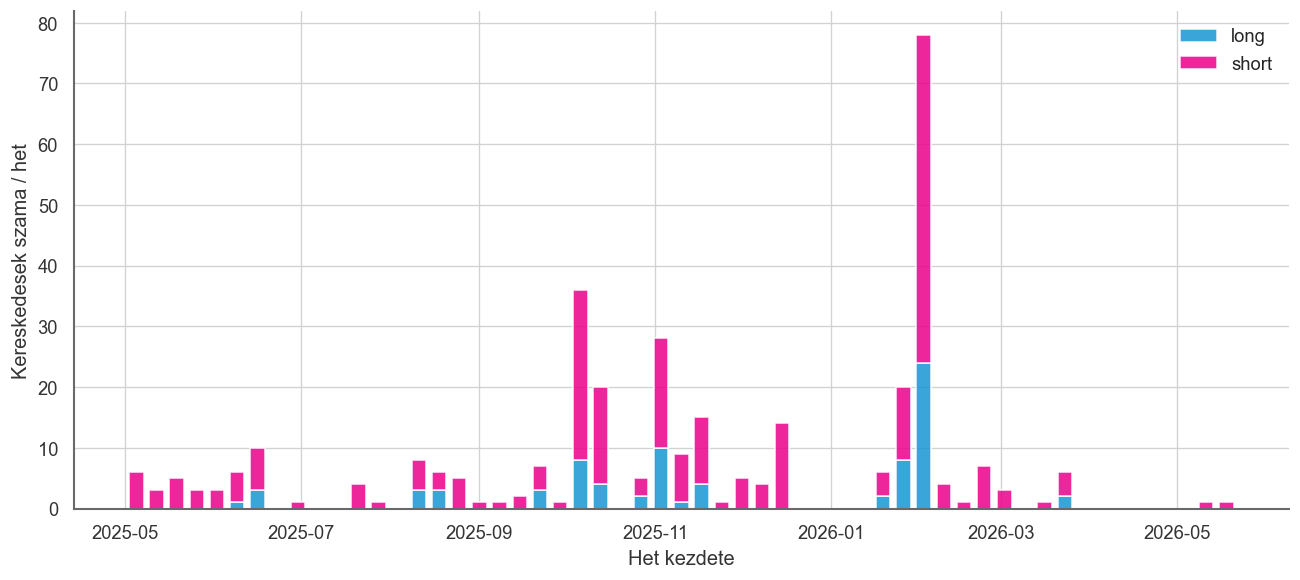

In [4]:
#| label: fig-backtest-weekly-trades
#| fig-cap: "Heti kereskedesszam a kalibracios periodusban, long vs short"
#| fig-alt: "Bar chart of weekly trade counts during the calibration/backtest period, split by long and short direction."

pivot_bt = wk_backtest.pivot(index="week_start", columns="direction", values="n_trades").fillna(0)
fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(pivot_bt.index, pivot_bt.get("long", 0), width=5, color=CQ_COLORS["blue"], label="long", alpha=0.85)
ax.bar(pivot_bt.index, pivot_bt.get("short", 0), width=5, bottom=pivot_bt.get("long", 0), color=CQ_COLORS["red"], label="short", alpha=0.85)
ax.set_xlabel("Het kezdete")
ax.set_ylabel("Kereskedesek szama / het")
ax.legend()
plt.tight_layout()
plt.show()

## 3. Heti signal-gyakorisag elesen, bevezetes utan

**Mi ez.** Elo tenyleges kereskedesi naplo (`trading.duckdb` -> `trading_positions`
/ `trading_signals`) ures - a live service dry-run modban futott csak roviden,
valodi eles run meg nem tortent hosszabb ideig. Ezert a signal-gyakorisagot a
`predictions` tabla nyers score-jaibol rekonstrualjuk, pontosan a live
runtime dontesi logikajat koveteve (`_doc_/database_and_code_doc/7100_live_trading.md`):
rank-percentile lookup a kalibracios eloszlason (`rank_lookup_long/short.parquet`),
majd `score_pct_long >= 0.98` (long) es `(1 - score_pct_short) >= 0.94` (short)
kuszob. Egymast koveto minosito percek egy "signal esemenynek" szamitanak
(max_hold_minutes=60 perces minimum tavolsaggal az esemenyek kozott, ahogy
egy valodi pozicio is lekotne ennyi idore a rendszert).

**Forras.** `solusdt.duckdb` -> `predictions` (`long_pred`, `short_pred`,
`long_model_id`, `short_model_id`); `rank_lookup_long/short.parquet` a
kalibracios artifactbol.

**Modszer.** `np.interp` a rank-lookup tablan (ugyanaz a modszer, mint a live
service `strategy.evaluate()` hivasa), majd elenkenti esemenydetektalas.

**Ertelmezes.** Ha ez az elo rata drasztikusan es aranytalanul (csak az egyik
iranyban) esik a kalibracios ratahoz kepest, az implementacios hibara utal.
Ha mindket irany aranyosan esik, az inkabb piaci rezsimvaltasra utal.

In [5]:
#| label: tbl-recomputed-signal-events
#| tbl-cap: "Rekonstrualt signal esemenyek kalibracios vs elo periodusban, iranybontasban"

main_con = dbu.connect()
q_pred = (
    "select open_time, long_pred, short_pred, long_model_id, short_model_id "
    "from predictions "
    f"where open_time >= '{FIT_START}' "
    f"and long_model_id = '{LONG_MODEL_ID}' "
    "order by open_time"
)
pred = main_con.execute(q_pred).df()
pred["open_time"] = pd.to_datetime(pred["open_time"])

rank_long = pd.read_parquet(LONG_STRAT_DIR / "rank_lookup_long.parquet")
rank_short = pd.read_parquet(SHORT_STRAT_DIR / "rank_lookup_short.parquet")

pred["score_pct_long"] = np.interp(pred["long_pred"], rank_long["score_raw"], rank_long["score_pct"])
pred["score_pct_short"] = np.interp(pred["short_pred"], rank_short["score_raw"], rank_short["score_pct"])
pred["long_qual"] = pred["score_pct_long"] >= LONG_CUTOFF
pred["short_qual"] = (1 - pred["score_pct_short"]) >= SHORT_CUTOFF
pred["period"] = np.where(pred["open_time"] >= LIVE_START, "live", "backtest_fit")


def edge_events(sub: pd.DataFrame, col: str, min_gap_minutes: int = 60) -> list:
    """Collapse consecutive qualifying bars into discrete signal-onset events."""
    qual = sub[col].to_numpy()
    times = sub["open_time"].to_numpy()
    events, last_t = [], None
    for i in range(len(qual)):
        if qual[i] and (last_t is None or (times[i] - last_t) >= np.timedelta64(min_gap_minutes, "m")):
            events.append(times[i])
            last_t = times[i]
    return events


rows = []
for period, sub in pred.groupby("period"):
    span_weeks = (sub["open_time"].max() - sub["open_time"].min()).total_seconds() / 86400 / 7
    for direction, col in [("long", "long_qual"), ("short", "short_qual")]:
        n_events = len(edge_events(sub, col))
        rows.append({
            "period": period, "direction": direction,
            "span_weeks": span_weeks, "signal_events": n_events,
            "events_per_week": n_events / span_weeks,
        })
recomputed_summary = pd.DataFrame(rows).sort_values(["direction", "period"])
display_analysis_table(recomputed_summary)

period,direction,span_weeks,signal_events,events_per_week
backtest_fit,long,59.819,52,0.869
live,long,7.094,1,0.141
backtest_fit,short,59.819,178,2.976
live,short,7.094,4,0.564


In [6]:
#| label: tbl-frequency-comparison
#| tbl-cap: "Heti signal-gyakorisag: kalibracio (tenyleges trades) vs elo (rekonstrualt)"

comp = summary_backtest.rename(columns={"trades_per_week": "calib_events_per_week"})[["direction", "calib_events_per_week"]]
live_rate = recomputed_summary[recomputed_summary["period"] == "live"][["direction", "events_per_week"]].rename(columns={"events_per_week": "live_events_per_week"})
comp = comp.merge(live_rate, on="direction")
# fraction, not pre-scaled to percent: display_analysis_table auto-scales *_pct columns whose
# values are already within [-1, 1] -- pre-multiplying here would double-scale negative deltas.
comp["relative_change_pct"] = comp["live_events_per_week"] / comp["calib_events_per_week"] - 1
display_analysis_table(comp)

direction,calib_events_per_week,live_events_per_week,relative_change_pct
long,1.382,0.141,-89.80%
short,4.608,0.564,-87.76%


## 4. Teljes idovonal - mikor kezdodott a csokkenes

**Mi ez.** A kalibracios percentilis-eloszlashoz mert heti atlagos
`score_pct_long` es `score_pct_short` alakulasa a teljes kalibracios ablaktol
(2025-05) a mai napig, jelolve a bevezetes (2026-06-23) idopontjat.

**Forras.** A 3. szekcioban szamitott `pred` DataFrame, heti bontasban.

**Modszer.** Heti atlag `score_pct_long` / `score_pct_short`, plusz a heti
minosito percek szama iranybontasban.

**Ertelmezes.** Ha a csokkenes mar a bevezetes elott, folytonosan elindult,
az arra utal, hogy a jelenseg nem a kodvaltashoz vagy a deploy esemenyhez
kotheto, hanem egy, a kalibracios ablaknal korabban kezdodott piaci
folyamathoz.

In [7]:
pred["week_start"] = pred["open_time"].dt.to_period("W-MON").dt.start_time
weekly_scores = pred.groupby("week_start").agg(
    mean_score_pct_long=("score_pct_long", "mean"),
    mean_score_pct_short=("score_pct_short", "mean"),
    long_qual_bars=("long_qual", "sum"),
    short_qual_bars=("short_qual", "sum"),
).reset_index()

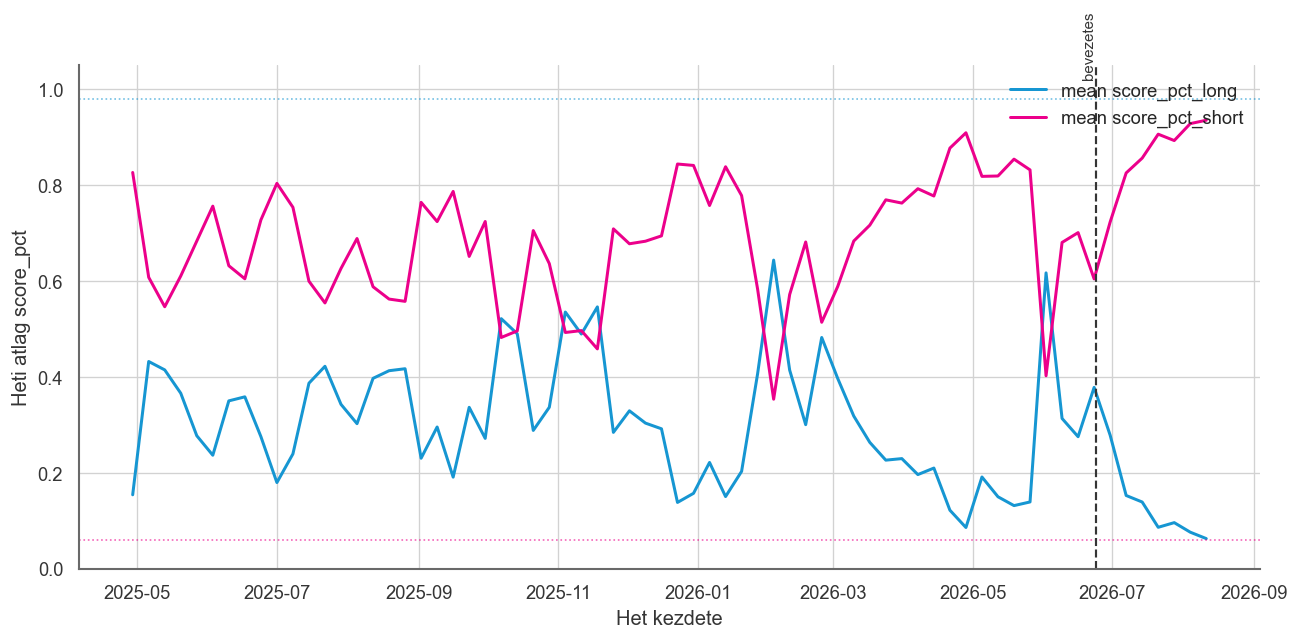

In [8]:
#| label: fig-weekly-score-trend
#| fig-cap: "Heti atlagos score_pct trend a kalibracios eloszlashoz merve, bevezetes jelolve"
#| fig-alt: "Line chart of weekly mean score percentile for long and short direction, with a vertical line marking the deployment date."

fig, ax = plt.subplots(figsize=(11, 5.5))
ax.plot(weekly_scores["week_start"], weekly_scores["mean_score_pct_long"], color=CQ_COLORS["blue"], lw=1.8, label="mean score_pct_long")
ax.plot(weekly_scores["week_start"], weekly_scores["mean_score_pct_short"], color=CQ_COLORS["red"], lw=1.8, label="mean score_pct_short")
ax.axhline(LONG_CUTOFF, color=CQ_COLORS["blue"], ls=":", lw=1, alpha=0.6)
ax.axhline(1 - SHORT_CUTOFF, color=CQ_COLORS["red"], ls=":", lw=1, alpha=0.6)
ax.axvline(ACTIVATED_AT, color=CQ_COLORS["gray_dark"], ls="--", lw=1.3)
ax.text(ACTIVATED_AT, 1.02, "bevezetes", rotation=90, va="bottom", ha="right", fontsize=9, color=CQ_COLORS["gray_dark"])
ax.set_xlabel("Het kezdete")
ax.set_ylabel("Heti atlag score_pct")
ax.set_ylim(0, 1.05)
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

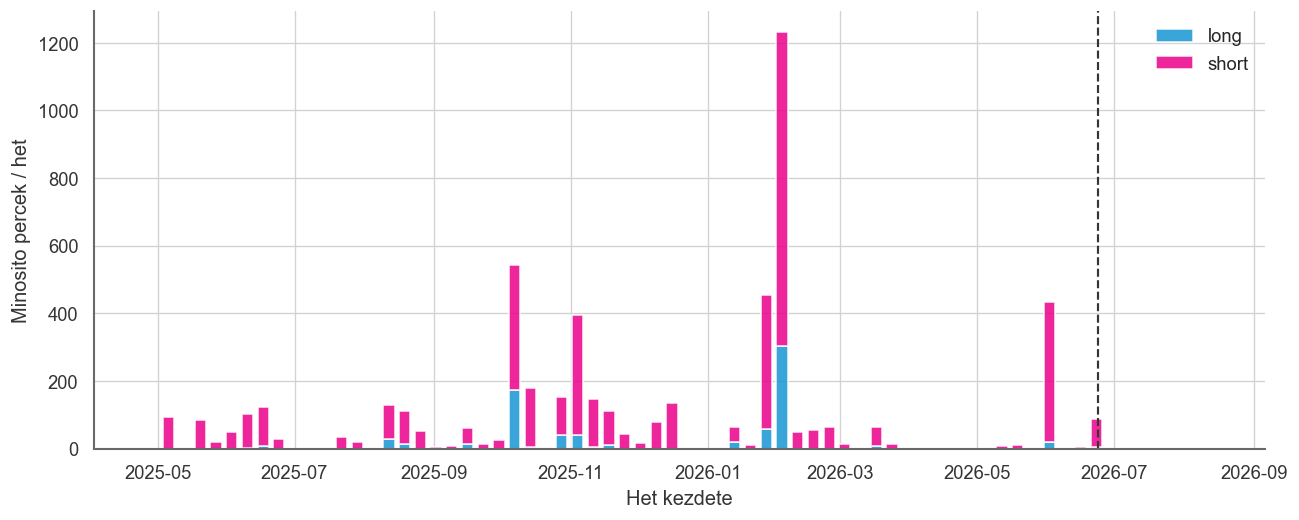

In [9]:
#| label: fig-weekly-qualifying-bars
#| fig-cap: "Heti minosito percek szama (entry_cutoff felett), long vs short"
#| fig-alt: "Bar chart of weekly count of bars crossing the entry threshold, long and short."

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.bar(weekly_scores["week_start"], weekly_scores["long_qual_bars"], width=5, color=CQ_COLORS["blue"], alpha=0.85, label="long")
ax.bar(weekly_scores["week_start"], weekly_scores["short_qual_bars"], width=5, bottom=weekly_scores["long_qual_bars"], color=CQ_COLORS["red"], alpha=0.85, label="short")
ax.axvline(ACTIVATED_AT, color=CQ_COLORS["gray_dark"], ls="--", lw=1.3)
ax.set_xlabel("Het kezdete")
ax.set_ylabel("Minosito percek / het")
ax.legend()
plt.tight_layout()
plt.show()

## 5. Implementacios hiba kizarasa

**Mi ez.** Harom ellenorzes annak kizarasara, hogy a jelenseg kodhiba (pl. egy
feature, ami elesen nem elerheto, de a treningen/kalibracion igen):

1. A `predictions` tabla `long_model_id`/`short_model_id` stampje a bevezetes
   ota konzisztensen a champion modellre mutat-e (nincs fallback/regi modell).
2. `long_pred`/`short_pred` nem NULL-e elesen egyetlen sorban sem.
3. A hosszu modell 57 feature-enek NaN-rataja a `feat_ohlcv_quant`-ban
   megegyezik-e (kozel nullara) eloben es a kalibracios ablakban.

**Forras.** `solusdt.duckdb` -> `predictions`, `feat_ohlcv_quant`;
`artifacts/<model_id>/features.json`.

**Modszer.** Egyszeru aggregalo lekerdezesek, csoportositva a modell-stamp es
periodus szerint.

**Ertelmezes.** Ha mindharom ellenorzes tiszta, a "hianyzo elo valtozo" hipotezis
elvetheto, es a magyarazatot piaci/rezsim oldalon kell keresni.

In [10]:
#| label: tbl-model-stamp-check
#| tbl-cap: "Model-id stamp konzisztencia es NULL predikcio ellenorzes az elo periodusban"

q_stamp = (
    "select long_model_id, short_model_id, count(*) as n, "
    "sum(case when long_pred is null then 1 else 0 end) as null_long_pred, "
    "sum(case when short_pred is null then 1 else 0 end) as null_short_pred, "
    "min(open_time) as min_time, max(open_time) as max_time "
    "from predictions "
    f"where open_time >= '{LIVE_START}' "
    "group by 1, 2"
)
model_stamp_check = main_con.execute(q_stamp).df()
display_analysis_table(model_stamp_check)

long_model_id,short_model_id,n,null_long_pred,null_short_pred,min_time,max_time
lgbm_solusdt_l_fw60_2101_2605,lgbm_solusdt_s_fw60_2101_2605,71500,0.000,0.000,2026-06-23 17:34:00,2026-08-12 09:18:00


In [11]:
#| label: tbl-feature-nan-check
#| tbl-cap: "Feature NaN-rata osszehasonlitas a hosszu modell 57 feature-ere, kalibracio vs elo"

import json as _json
feats = _json.loads((ARTIFACTS / LONG_MODEL_ID / "features.json").read_text())["features"]

nan_rows = []
for f in feats:
    q_nan = (
        f'select sum(case when open_time >= \'{FIT_START}\' and open_time < \'{LIVE_START}\' '
        f'and "{f}" is null then 1 else 0 end) as null_backtest, '
        f'sum(case when open_time >= \'{LIVE_START}\' and "{f}" is null then 1 else 0 end) as null_live '
        f'from feat_ohlcv_quant where open_time >= \'{FIT_START}\''
    )
    r = main_con.execute(q_nan).fetchone()
    nan_rows.append({"feature": f, "null_count_backtest": r[0], "null_count_live": r[1]})
nan_df = pd.DataFrame(nan_rows)
nan_summary = pd.DataFrame([
    {"metric": "features checked", "value": len(feats)},
    {"metric": "features with any NaN (backtest window)", "value": int((nan_df["null_count_backtest"] > 0).sum())},
    {"metric": "features with any NaN (live window)", "value": int((nan_df["null_count_live"] > 0).sum())},
    {"metric": "max NaN count, any feature, backtest", "value": int(nan_df["null_count_backtest"].max())},
    {"metric": "max NaN count, any feature, live", "value": int(nan_df["null_count_live"].max())},
])
display_analysis_table(nan_summary)

metric,value
features checked,57
features with any NaN (backtest window),6
features with any NaN (live window),0
"max NaN count, any feature, backtest",48
"max NaN count, any feature, live",0


## 6. Piaci rezsim - volatilitas osszehasonlitas

**Mi ez.** Volatilitas-jellegu feature-ok (ATR14, NATR14, historikus
volatilitas) medianjanak osszevetese a kalibracios es az elo periodus kozott.

**Forras.** `feat_ohlcv_quant` -> `feat_atr_14`, `feat_natr_14`, `feat_hist_vol_20`.

**Modszer.** Median aggregacio periodusonkent (robusztusabb, mint az atlag
short-tail eloszlasoknal).

**Ertelmezes.** Ha a volatilitas elesen tartosan alacsonyabb, mint a
kalibracios ablakban, az onmagaban megmagyarazza, hogy a modell nyers
score-jai (amik a volatilitastol fuggo MFE-t becslik) ritkabban erik el a
kalibracios eloszlas magas percentiliseit - anelkul, hogy barmi hibas lenne
a pipeline-ban.

In [12]:
#| label: tbl-volatility-regime-comparison
#| tbl-cap: "Volatilitas medianok osszehasonlitasa: kalibracios vs elo periodus"

q_vol = (
    "select case when open_time >= '" + LIVE_START + "' then 'live' else 'backtest_fit' end as period, "
    "median(feat_atr_14) as median_atr_14, "
    "median(feat_natr_14) as median_natr_14, "
    "median(feat_hist_vol_20) as median_hist_vol_20 "
    "from feat_ohlcv_quant "
    "where open_time >= '" + FIT_START + "' "
    "group by 1"
)
vol_compare = main_con.execute(q_vol).df()
live_row = vol_compare.loc[vol_compare["period"] == "live"].iloc[0]
bt_row = vol_compare.loc[vol_compare["period"] == "backtest_fit"].iloc[0]
vol_cols = ["median_atr_14", "median_natr_14", "median_hist_vol_20"]
# fraction, not pre-scaled to percent -- display_analysis_table auto-scales *_pct columns
# whose values sit within [-1, 1]; pre-multiplying here would double-scale negative deltas.
change_row = {c.replace("median_", "") + "_change_pct": live_row[c] / bt_row[c] - 1 for c in vol_cols}
vol_compare = vol_compare.assign(**{k: np.nan for k in change_row})
for k, v in change_row.items():
    vol_compare.loc[vol_compare["period"] == "live", k] = v
display_analysis_table(vol_compare)

period,median_atr_14,median_natr_14,median_hist_vol_20,atr_14_change_pct,natr_14_change_pct,hist_vol_20_change_pct
live,0.057,0.001,0.001,-61.52%,-31.51%,-29.15%
backtest_fit,0.148,0.001,0.001,—,—,—


## Ertelmezes

In [13]:
long_calib_rate = comp.loc[comp["direction"] == "long", "calib_events_per_week"].iloc[0]
long_live_rate = comp.loc[comp["direction"] == "long", "live_events_per_week"].iloc[0]
short_calib_rate = comp.loc[comp["direction"] == "short", "calib_events_per_week"].iloc[0]
short_live_rate = comp.loc[comp["direction"] == "short", "live_events_per_week"].iloc[0]
long_drop = comp.loc[comp["direction"] == "long", "relative_change_pct"].iloc[0] * 100
short_drop = comp.loc[comp["direction"] == "short", "relative_change_pct"].iloc[0] * 100
atr_change = float(vol_compare.loc[vol_compare["period"] == "live", "atr_14_change_pct"].iloc[0]) * 100
max_nan_live = int(nan_df["null_count_live"].max())
n_model_stamps = model_stamp_check.shape[0]

verdict_bug_ruled_out = (max_nan_live == 0) and (n_model_stamps == 1) and (model_stamp_check["null_long_pred"].sum() == 0)

md_lines = [
    "",
    "A kalibracios periodusban (" + FIT_START + " - " + FIT_END + ") a short irany mar",
    "alapbol **{:.1f}x** gyakrabban adott".format(short_calib_rate / long_calib_rate),
    "belepo jelzest, mint a long ({:.2f} vs {:.2f}".format(long_calib_rate, short_calib_rate),
    "esemeny/het) - ez a ket irany eltero, aszimmetrikus entry_cutoff-jabol",
    "kovetkezik (long p98, azaz felso 2%; short p94, azaz also 6% a rangsorban),",
    "nem bevezetes utani anomalia.",
    "",
    "Bevezetes ota mindket irany gyakorisaga **aranyosan** visszaesett:",
    "long {:+.0f}%, short {:+.0f}% a kalibracios ratahoz".format(long_drop, short_drop),
    "kepest ({:.2f} es {:.2f} esemeny/het). A".format(long_live_rate, short_live_rate),
    "heti trend chart (4. szekcio) azt mutatja, hogy ez a visszaeses **nem a",
    "bevezetes napjaval egybeeso lepes**, hanem egy mar 2026 aprilisa ota -",
    "tehat joval a deploy elott, meg a kalibracios ablakon belul - folyamatosan",
    "zajlo csokkenes folytatasa.",
    "",
    "Az implementacios hiba hipotezist (5. szekcio) az adat nem tamasztja ala:",
    "a `predictions` tabla model-stampje a teljes elo ablakban egysegesen a",
    "champion modellekre mutat, `long_pred`/`short_pred` egyetlen sorban sem NULL,",
    "es a hosszu modell mind az 57 feature-e gyakorlatilag NaN-mentes mind a",
    "kalibracios, mind az elo ablakban (max {} NaN eloben).".format(max_nan_live),
    "",
    "Ezzel szemben a volatilitas-osszehasonlitas (6. szekcio) objektiv, merheto",
    "magyarazatot ad: az elo ablak median ATR14 erteke {:+.0f}%-kal".format(atr_change),
    "ter el a kalibracios ablaktol. Mivel mindket modell egy volatilitasfuggo MFE",
    "targetet becsul, egy tartosan alacsonyabb volatilitasu rezsimben a nyers",
    "score-ok szisztematikusan a kalibracios eloszlas alsobb percentiliseibe",
    "esnek - ez mindket iranyban ritkabb jelzest okoz, es mivel a long kuszobe",
    "eleve szigorubb (top 2% vs also 6%), a long irany esik kozelebb a nullahoz,",
    "mikozben a short meg idonkent atlepi a sajat, lazabb kuszobet. Ez pontosan",
    "azt a megfigyelest adja, amit a user leirt: \"short gyakori, long szinte",
    "soha\" - anelkul, hogy a long tenylegesen nullara esett volna.",
    "",
    "**Dontesi szempont:** a jelenseg jelenlegi bizonyitekok alapjan elsosorban",
    "**piaci rezsimvaltasra / kalibracios drift-re** vezetheto vissza, nem kodhibara.",
    "A fix, egy evvel korabbi ablakon kalibralt percentil-kuszobok egy tartosan",
    "alacsonyabb volatilitasu piacon szuksegszeruen ritkabban lepnek tul -",
    "ez a `rank_first` + fix `entry_cutoff` architektura ismert korlatja, nem",
    "regresszio. Javasolt kovetkezo lepes: a kalibracios ablak frissitese /",
    "rendszeres ujrakalibralas bevezetese (rolling recalibration), vagy a",
    "long entry_cutoff felulvizsgalata, mielott kodszintu hibakeresesbe kezdunk.",
    "Nem zarhato ki teljesen egy finomabb, csak ertek-szintu (nem NULL) feature-",
    "szamitasi elteres elo es offline szinkron kozott - ha a rezsim-magyarazat",
    "gyakorlati dontes utan is ketseges marad, egy dedikalt, bar-szintu",
    "feature-ertek paritas-teszt (elo sync vs offline ujraszamitas ugyanarra az",
    "idoszakra) lenne a kovetkezo diagnosztikai lepes.",
]
display(Markdown("\n".join(md_lines)))


A kalibracios periodusban (2025-05-01 - 2026-05-31) a short irany mar
alapbol **3.3x** gyakrabban adott
belepo jelzest, mint a long (1.38 vs 4.61
esemeny/het) - ez a ket irany eltero, aszimmetrikus entry_cutoff-jabol
kovetkezik (long p98, azaz felso 2%; short p94, azaz also 6% a rangsorban),
nem bevezetes utani anomalia.

Bevezetes ota mindket irany gyakorisaga **aranyosan** visszaesett:
long -90%, short -88% a kalibracios ratahoz
kepest (0.14 es 0.56 esemeny/het). A
heti trend chart (4. szekcio) azt mutatja, hogy ez a visszaeses **nem a
bevezetes napjaval egybeeso lepes**, hanem egy mar 2026 aprilisa ota -
tehat joval a deploy elott, meg a kalibracios ablakon belul - folyamatosan
zajlo csokkenes folytatasa.

Az implementacios hiba hipotezist (5. szekcio) az adat nem tamasztja ala:
a `predictions` tabla model-stampje a teljes elo ablakban egysegesen a
champion modellekre mutat, `long_pred`/`short_pred` egyetlen sorban sem NULL,
es a hosszu modell mind az 57 feature-e gyakorlatilag NaN-mentes mind a
kalibracios, mind az elo ablakban (max 0 NaN eloben).

Ezzel szemben a volatilitas-osszehasonlitas (6. szekcio) objektiv, merheto
magyarazatot ad: az elo ablak median ATR14 erteke -62%-kal
ter el a kalibracios ablaktol. Mivel mindket modell egy volatilitasfuggo MFE
targetet becsul, egy tartosan alacsonyabb volatilitasu rezsimben a nyers
score-ok szisztematikusan a kalibracios eloszlas alsobb percentiliseibe
esnek - ez mindket iranyban ritkabb jelzest okoz, es mivel a long kuszobe
eleve szigorubb (top 2% vs also 6%), a long irany esik kozelebb a nullahoz,
mikozben a short meg idonkent atlepi a sajat, lazabb kuszobet. Ez pontosan
azt a megfigyelest adja, amit a user leirt: "short gyakori, long szinte
soha" - anelkul, hogy a long tenylegesen nullara esett volna.

**Dontesi szempont:** a jelenseg jelenlegi bizonyitekok alapjan elsosorban
**piaci rezsimvaltasra / kalibracios drift-re** vezetheto vissza, nem kodhibara.
A fix, egy evvel korabbi ablakon kalibralt percentil-kuszobok egy tartosan
alacsonyabb volatilitasu piacon szuksegszeruen ritkabban lepnek tul -
ez a `rank_first` + fix `entry_cutoff` architektura ismert korlatja, nem
regresszio. Javasolt kovetkezo lepes: a kalibracios ablak frissitese /
rendszeres ujrakalibralas bevezetese (rolling recalibration), vagy a
long entry_cutoff felulvizsgalata, mielott kodszintu hibakeresesbe kezdunk.
Nem zarhato ki teljesen egy finomabb, csak ertek-szintu (nem NULL) feature-
szamitasi elteres elo es offline szinkron kozott - ha a rezsim-magyarazat
gyakorlati dontes utan is ketseges marad, egy dedikalt, bar-szintu
feature-ertek paritas-teszt (elo sync vs offline ujraszamitas ugyanarra az
idoszakra) lenne a kovetkezo diagnosztikai lepes.